## **Projeto Final – Arranjo Automático de Acompanhamento de Piano para Melodias Pop com Transformer e Representação REMI: Comparação com uma RNN Vanilla no Dataset POP909**

**IA Generativa para Música**

**Aluno: Gustavo Santos Silva**

### 0 - Instalação de Dependências e Importação de Bibliotecas

In [ ]:
!pip -q install mido
!pip -q install "miditok>=3.0"
!pip -q install pretty_midi pyfluidsynth
!pip -q install muspy
!apt-get -qq install -y fluidsynth fluid-soundfont-gm > /dev/null

In [ ]:
import os
import glob
import json
import random
import pickle
import math
import time
import shutil
import numpy as np
import pandas as pd
import mido
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import pretty_midi
import muspy
from collections import Counter, defaultdict
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from symusic import Score, Track, Note, TimeSignature
from miditok import REMI, TokenizerConfig
from scipy.io import wavfile
from IPython.display import Audio, display

### 1 - Dataset

#### 1.1 -  Download dos Dados

In [ ]:
if not os.path.exists("POP909-Dataset"):
    !git clone --depth 1 -q https://github.com/music-x-lab/POP909-Dataset.git

midis = sorted(glob.glob("POP909-Dataset/POP909/*/*.mid"))
print("Arquivos MIDI:", len(midis))

Arquivos MIDI: 909


#### 1.2 - Separação dos Dados em Treino/Validação/Teste

In [ ]:
DATASET = "POP909-Dataset"

musicas = sorted(
    d for d in os.listdir(f"{DATASET}/POP909")
    if os.path.isfile(f"{DATASET}/POP909/{d}/{d}.mid")
)
print("Músicas com MIDI:", len(musicas))

SEED = 42
random.Random(SEED).shuffle(musicas)

n = len(musicas)
n_val = round(0.10 * n)
n_test = round(0.10 * n)
n_train = n - n_val - n_test

particao = {
    "train": sorted(musicas[:n_train]),
    "val":   sorted(musicas[n_train:n_train + n_val]),
    "test":  sorted(musicas[n_train + n_val:]),
}

print("Tamanho dos Conjuntos: ",{k: len(v) for k, v in particao.items()})

with open("particao.json", "w") as f:
    json.dump(particao, f)

Músicas com MIDI: 909
Tamanho dos Conjuntos:  {'train': 727, 'val': 91, 'test': 91}


#### 1.3 - Pré-Processamento dos Dados

**O código dessa parte é baseado no código dos idealizadores do dataset "POP909 - Dataset for Music Arrangement Generation"**

**FONTE: https://github.com/music-x-lab/POP909-Dataset**

In [ ]:
# PARÂMETROS DE PRÉ-PROCESSAMENTO
DATASET = "POP909-Dataset/POP909"
BAR = 16
WIN_BARS = 4
MIN_MEL = 4
MIN_ACC = 8
MIN_COBERTURA = 0.90
FILTRAR_COMPASSO = False

particao = json.load(open("particao.json"))


# FUNÇÕES DE PRÉ-PROCESSAMENTO
def ler_midi(path):
    mid = mido.MidiFile(path)
    tracks = {}
    compassos = []
    tempos = []
    for tr in mid.tracks:
        t = 0
        abertas = defaultdict(list)
        notas = []
        for msg in tr:
            t += msg.time
            if msg.type == "time_signature":
                compassos.append((msg.numerator, msg.denominator))
            elif msg.type == "set_tempo":
                tempos.append(mido.tempo2bpm(msg.tempo))
            elif msg.type == "note_on" and msg.velocity > 0:
                abertas[msg.note].append(t)
            elif msg.type in ("note_off", "note_on") and abertas[msg.note]:
                ini = abertas[msg.note].pop(0)
                notas.append((ini, t - ini, msg.note))
        if notas:
            tracks[tr.name.strip().upper()] = np.array(notas)
    return tracks, compassos, tempos, mid.ticks_per_beat / 4

def quantizar(a, step):
    t = np.round(a[:, 0] / step).astype(int)
    d = np.maximum(1, np.round(a[:, 1] / step)).astype(int)
    p = a[:, 2].astype(int)
    _, idx = np.unique(t * 128 + p, return_index=True)
    return t[idx], d[idx], p[idx]

def preprocessar(path):
    tracks, compassos, tempos, step = ler_midi(path)
    if "MELODY" not in tracks or "PIANO" not in tracks:
        return None, "trilhas_ausentes"
    if FILTRAR_COMPASSO and any(n % 4 != 0 for n, _ in compassos):
        return None, "compasso_nao_4"
    mel = quantizar(tracks["MELODY"], step)
    acc = quantizar(tracks["PIANO"], step)
    if len(mel[0]) < MIN_MEL or len(acc[0]) < MIN_ACC:
        return None, "poucas_notas"
    mb = set(mel[0] // BAR)
    ac = set(acc[0] // BAR)
    if len(mb & ac) / len(mb) < MIN_COBERTURA:
        return None, "desalinhamento_melodia_piano"
    n_bars = int(max((mel[0] + mel[1]).max(), (acc[0] + acc[1]).max()) // BAR) + 1
    return {
        "mel": mel,
        "acc": acc,
        "n_bars": n_bars,
        "compasso": compassos[0] if compassos else None,
        "bpm": float(np.median(tempos)) if tempos else None
    }, "ok"

def recortar(notas, lo, hi):
    t, d, p = notas
    m = (t >= lo) & (t < hi)
    return t[m] - lo, np.minimum(d[m], hi - t[m]), p[m]


# EXECUÇÃO DO PRÉ-PROCESSAMENTO
songs = {}
motivos = Counter()
for split, ids in particao.items():
    for sid in tqdm(ids, desc=f"Lendo {split}"):
        try:
            s, why = preprocessar(f"{DATASET}/{sid}/{sid}.mid")
        except Exception as e:
            s = None
            why = "erro_" + type(e).__name__
        motivos[(split, why)] += 1
        if s:
            songs[sid] = s

janelas = {"train": [], "val": [], "test": []}
descartes_janela = Counter()
for split, ids in particao.items():
    for sid in ids:
        if sid not in songs:
            continue
        s = songs[sid]
        for b0 in range(0, s["n_bars"] - WIN_BARS + 1, WIN_BARS):
            lo = b0 * BAR
            hi = (b0 + WIN_BARS) * BAR
            mel = recortar(s["mel"], lo, hi)
            acc = recortar(s["acc"], lo, hi)
            if len(mel[0]) < MIN_MEL or len(acc[0]) < MIN_ACC:
                descartes_janela["poucas_notas"] += 1
                continue
            if min(mel[2].min(), acc[2].min()) < 21 or max(mel[2].max(), acc[2].max()) > 108:
                descartes_janela["fora_da_faixa_do_piano" ] += 1
                continue
            janelas[split].append({
                "song": sid,
                "bar0": b0,
                "mel": mel,
                "acc": acc,
                "bpm": s["bpm"]
            })


pickle.dump({"songs": songs, "janelas": janelas}, open("dados_pre.pkl", "wb"))

Lendo train:   0%|          | 0/727 [00:00<?, ?it/s]

Lendo val:   0%|          | 0/91 [00:00<?, ?it/s]

Lendo test:   0%|          | 0/91 [00:00<?, ?it/s]

#### 1.4 - Estatísticas dos Dados


Dados após Pré-processamento:
partição  músicas  janelas  notas melodia/janela (média)  notas acomp./janela (média)
   train      724    12075                          20.2                         53.8
     val       90     1493                          20.2                         53.8
    test       91     1495                          20.5                         53.4

Altura MIDI — melodia: 42–98 (mediana 72) | piano: 24–102 (mediana 59)
Compassos por música: média 83.8 | Andamento (bpm) mediano: 74 [37–197]



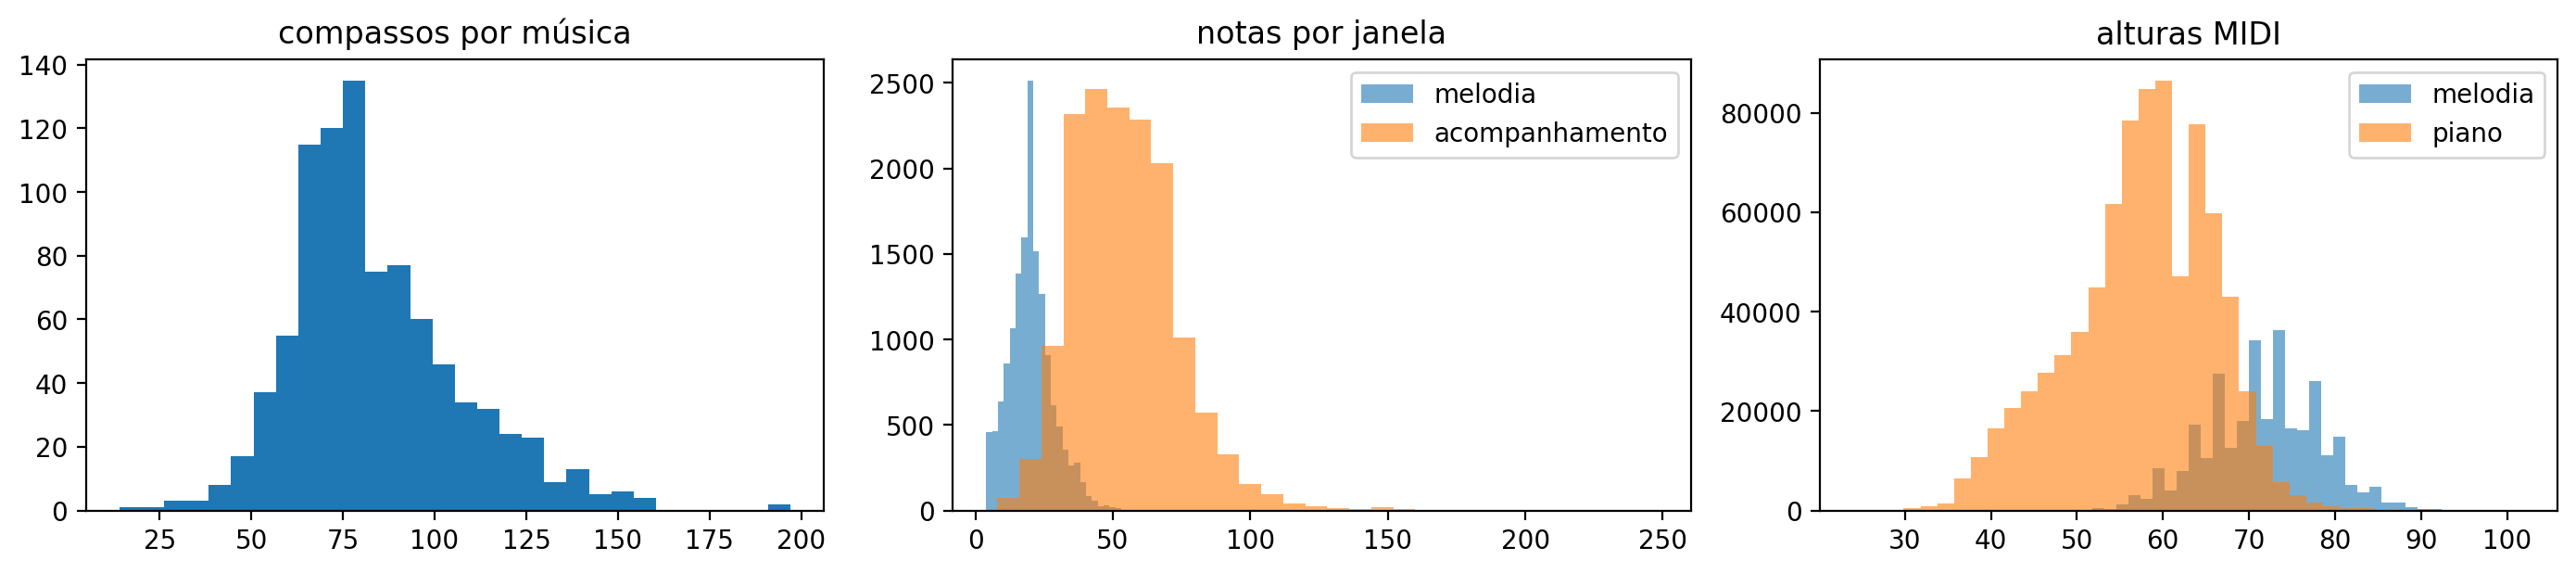

In [ ]:
linhas = []
for split in ("train", "val", "test"):
    J = janelas[split]
    linhas.append({
        "partição": split,
        "músicas": sum(1 for sid in particao[split] if sid in songs),
        "janelas": len(J),
        "notas melodia/janela (média)": round(np.mean([len(w["mel"][0]) for w in J]), 1),
        "notas acomp./janela (média)": round(np.mean([len(w["acc"][0]) for w in J]), 1),
    })
print("\nDados após Pré-processamento:")
print(pd.DataFrame(linhas).to_string(index=False))

todas = [w for J in janelas.values() for w in J]
mel_p = np.concatenate([w["mel"][2] for w in todas])
acc_p = np.concatenate([w["acc"][2] for w in todas])
bpms = [s["bpm"] for s in songs.values() if s["bpm"]]
print(f"\nAltura MIDI — melodia: {mel_p.min()}–{mel_p.max()} (mediana {np.median(mel_p):.0f}) | "
      f"piano: {acc_p.min()}–{acc_p.max()} (mediana {np.median(acc_p):.0f})")
print(f"Compassos por música: média {np.mean([s["n_bars"] for s in songs.values()]):.1f} | "
      f"Andamento (bpm) mediano: {np.median(bpms):.0f} [{np.min(bpms):.0f}–{np.max(bpms):.0f}]")
print("")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].hist([s["n_bars"] for s in songs.values()], bins=30)
ax[0].set_title("compassos por música")
ax[1].hist([len(w["mel"][0]) for w in todas], bins=30, alpha=.6, label="melodia")
ax[1].hist([len(w["acc"][0]) for w in todas], bins=30, alpha=.6, label="acompanhamento")
ax[1].legend()
ax[1].set_title("notas por janela")
ax[2].hist(mel_p, bins=40, alpha=.6, label="melodia")
ax[2].hist(acc_p, bins=40, alpha=.6, label="piano")
ax[2].legend()
ax[2].set_title("alturas MIDI")
plt.tight_layout()
plt.show()

### 2 - Representação

#### 2.1 - Tokenização dos Arquivos MIDI
**O código dessa parte é baseado no código dos idealizadores do MidiTok e no artigo "Pop Music Transformer: Beat-based Modeling and Generation of Expressive Pop Piano Compositions"**

**FONTE: https://github.com/Natooz/MidiTok**

In [ ]:
dados = pickle.load(open("dados_pre.pkl", "rb"))
janelas = dados["janelas"]

TPQ, STEP = 480, 120
WIN_BARS, MAX_LEN = 4, 768

# TOKENIZADOR REMI - miditok
config = TokenizerConfig(
    pitch_range=(21, 109),
    beat_res={(0, 4): 4, (4, 12): 2},
    special_tokens=["PAD", "BOS", "EOS", "SEP"],
    use_velocities=False,
    use_chords=False,
    use_rests=False,
    use_tempos=False,
    use_time_signatures=False,
    use_programs=False,
)
tokenizer = REMI(config)
vocab = tokenizer.vocab
V = len(tokenizer)
PAD, BOS, EOS, SEP = (vocab[k] for k in ("PAD_None", "BOS_None", "EOS_None", "SEP_None"))
BAR_ID = vocab["Bar_None"]
id2tok = {i: t for t, i in vocab.items()}
print("Tamanho do vocabulário:", V, "| PAD/BOS/EOS/SEP =", PAD, BOS, EOS, SEP)

# FUNÇÕES PARA TOKENIZADOR
def para_score(t, d, p):
    sc = Score(TPQ)
    sc.time_signatures.append(TimeSignature(0, 4, 4))
    tr = Track(program=0, is_drum=False, name="x")
    for a, b, c in zip(t, d, p):
        tr.notes.append(Note(time=int(a) * STEP, duration=int(b) * STEP, pitch=int(c), velocity=80))
    sc.tracks.append(tr)
    return sc

def tokenizar(t, d, p):
    saida = tokenizer.encode(para_score(t, d, p))
    seq = saida[0] if isinstance(saida, (list, tuple)) else saida
    return [int(i) for i in seq.ids]

def destokenizar(ids):
    ids = [i for i in ids if i not in (PAD, BOS, EOS, SEP)]
    sc = None
    for tentativa in (lambda: tokenizer.decode([ids]), lambda: tokenizer.decode(ids)):
        try:
            sc = tentativa()
            break
        except Exception:
            continue
    if sc is None or len(sc.tracks) == 0 or len(sc.tracks[0].notes) == 0:
        return np.zeros(0, int), np.zeros(0, int), np.zeros(0, int)
    n = sc.tracks[0].notes.numpy()
    k = 4.0 / sc.ticks_per_quarter
    return (
        np.round(n["time"] * k).astype(int),
        np.maximum(1, np.round(n["duration"] * k)).astype(int),
        n["pitch"].astype(int),
    )

# EXECUÇÃO DO TOKENIZADOR
dataset, descartadas = {}, Counter()
for split, J in janelas.items():
    dataset[split] = []
    for w in tqdm(J, desc=f"Tokenizando {split}"):
        m_ids, a_ids = tokenizar(*w["mel"]), tokenizar(*w["acc"])
        if len(m_ids) + len(a_ids) + 3 > MAX_LEN:
            descartadas[split] += 1
            continue
        dataset[split].append({
            "song": w["song"],
            "bar0": w["bar0"],
            "bpm": w["bpm"],
            "mel": m_ids,
            "acc": a_ids,
            "seq": [BOS] + m_ids + [SEP] + a_ids + [EOS],
            "sep": len(m_ids) + 1,
        })


pickle.dump(
    {
        "dataset": dataset,
        "V": V,
        "PAD": PAD,
        "BOS": BOS,
        "EOS": EOS,
        "SEP": SEP,
        "BAR": BAR_ID,
        "MAX_LEN": MAX_LEN,
        "WIN_BARS": WIN_BARS,
    },
    open("tokens.pkl", "wb"),
)
try:
    tokenizer.save("tokenizer.json")
except Exception as e:
    print("Aviso: não foi possível salvar o tokenizador:", e)

Tamanho do vocabulário: 204 | PAD/BOS/EOS/SEP = 0 1 2 3


Tokenizando train:   0%|          | 0/12075 [00:00<?, ?it/s]

Tokenizando val:   0%|          | 0/1493 [00:00<?, ?it/s]

Tokenizando test:   0%|          | 0/1495 [00:00<?, ?it/s]

#### 2.2 - Tamanho do Vocabulário e Comprimento Médio das Sequências

Tamanho do vocabulário: 204 

partição  janelas melodia (média ± dp) acompanhamento (média ± dp) sequência total (média ± dp)  mediana  máximo
   train    12075          64.6 ± 24.1                144.8 ± 46.2                 212.4 ± 61.2      205     581
     val     1493          64.3 ± 22.6                145.2 ± 45.6                 212.5 ± 58.9      207     719
    test     1495          65.2 ± 25.4                143.3 ± 43.9                 211.4 ± 58.3      203     397

Todas as partições: comprimento médio = 212.3 tokens com janelas de 4 compassos, limite de 768 tokens.


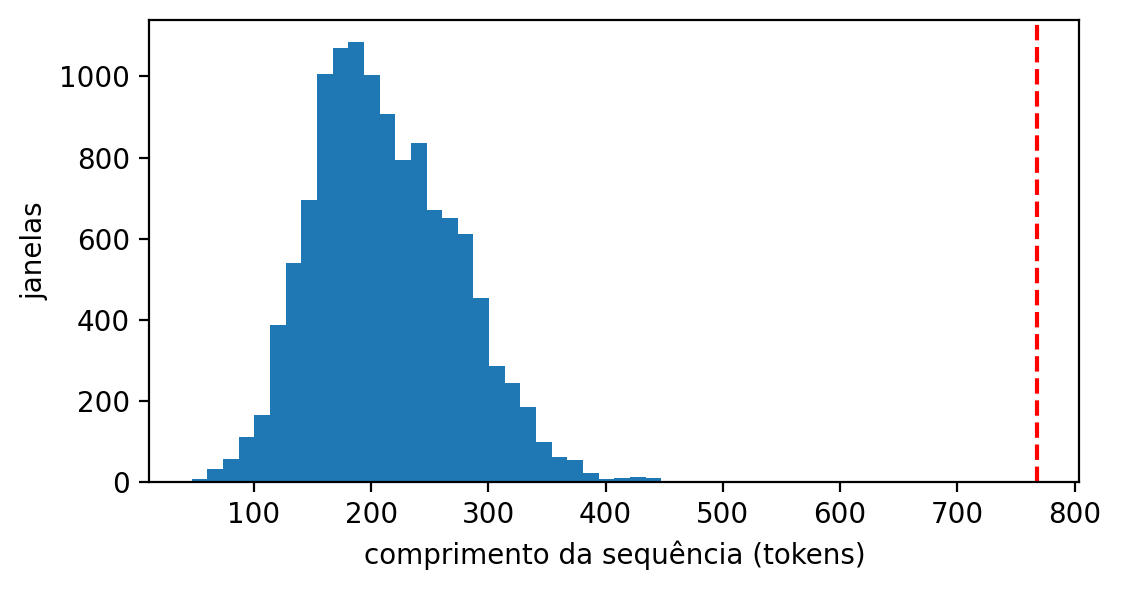

In [ ]:
d = pickle.load(open("tokens.pkl", "rb"))
dataset, V = d["dataset"], d["V"]

print("Tamanho do vocabulário:", V, "\n")

linhas = []
for split, D in dataset.items():
    lm = np.array([len(x["mel"]) for x in D])
    la = np.array([len(x["acc"]) for x in D])
    lt = np.array([len(x["seq"]) for x in D])
    linhas.append({
        "partição": split,
        "janelas": len(D),
        "melodia (média ± dp)": f"{lm.mean():.1f} ± {lm.std():.1f}",
        "acompanhamento (média ± dp)": f"{la.mean():.1f} ± {la.std():.1f}",
        "sequência total (média ± dp)": f"{lt.mean():.1f} ± {lt.std():.1f}",
        "mediana": int(np.median(lt)),
        "máximo": int(lt.max())
    })
print(pd.DataFrame(linhas).to_string(index=False))

todos = np.concatenate([[len(x["seq"]) for x in D] for D in dataset.values()])
print(f"\nTodas as partições: comprimento médio = {todos.mean():.1f} tokens "
      f"com janelas de {d['WIN_BARS']} compassos, limite de {d['MAX_LEN']} tokens.")

plt.figure(figsize=(6, 3))
plt.hist([len(x["seq"]) for x in dataset["train"]], bins=40)
plt.axvline(MAX_LEN, color="r", ls="--")
plt.xlabel("comprimento da sequência (tokens)")
plt.ylabel("janelas")
plt.show()

### 3 - Modelo - Transformer Decoder-only

#### 3.1 - Classe do Modelo

In [ ]:
# MODELO DO TRANSFORMER
class PianoTransformer(nn.Module):
    def __init__(self, vocab, d_model=256, n_heads=8, n_layers=6, d_ff=1024, dropout=0.1, max_len=MAX_LEN):
        super().__init__()
        self.d_model = d_model
        self.tok = nn.Embedding(vocab, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        self.drop = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, activation="gelu",
                                       batch_first=True, norm_first=True)
            for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, vocab, bias=False)
        self.out.weight = self.tok.weight
        nn.init.normal_(self.tok.weight, std=0.02)
        nn.init.normal_(self.pos.weight, std=0.02)

    def forward(self, x):
        T = x.size(1)
        h = self.tok(x) * math.sqrt(self.d_model) + self.pos(torch.arange(T, device=x.device))
        h = self.drop(h)
        causal = torch.ones(T, T, dtype=torch.bool, device=x.device).triu(1)
        for layer in self.layers:
            h = layer(h, src_mask=causal)
        return self.out(self.ln(h))

# IMPLEMENTAÇÃO DO DATASET DO PYTORCH
class PianoDataset(Dataset):
    def __init__(self, items):
        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        return self.items[idx]

# FUNÇÃO DE COLAÇÃO PARA PADDING DINÂMICO
def collate_fn(batch):
    L = max(len(x["seq"]) for x in batch)
    x_tensor = torch.full((len(batch), L), PAD, dtype=torch.long)
    sep = torch.tensor([x_["sep"] for x_ in batch])
    for k, it in enumerate(batch):
        x_tensor[k, :len(it["seq"])] = torch.tensor(it["seq"])
    inp, tgt = x_tensor[:, :-1], x_tensor[:, 1:].clone()
    tgt[(torch.arange(L - 1)[None, :] < sep[:, None]) | (tgt == PAD)] = -100
    return inp.to(dev), tgt.to(dev)

#### 3.2 - Avaliação e Laço de Treinamento
**Implementado com auxilio do tutorial "Sequence-to-Sequence Modeling with nn.Transformer and TorchText"**

**FONTE: https://h-huang.github.io/tutorials/beginner/transformer_tutorial.html**

In [ ]:
@torch.no_grad()
def avaliar(model, loader):
    model.eval()
    total, n = 0.0, 0
    for inp, tgt in loader:
        with torch.autocast(**AC):
            logits = model(inp)
        total += F.cross_entropy(logits.float().reshape(-1, V), tgt.reshape(-1), ignore_index=-100, reduction="sum").item()
        n += (tgt != -100).sum().item()
    return total / n

def treinar(model, epocas=15, batch_size=32, lr=5e-4, warmup=200, paciencia=3, caminho="transformer.pt"):
    model.to(dev)

    train_dataset = PianoDataset(dataset["train"])
    val_dataset = PianoDataset(dataset["val"])
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.98), weight_decay=0.01)
    passos_total = epocas * len(train_loader)
    def fator(s):
        if s < warmup:
            return (s + 1) / warmup
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, passos_total - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, fator)
    scaler = torch.amp.GradScaler("cuda", enabled=(dev == "cuda"))
    hist, melhor, ruim = {"train": [], "val": []}, float("inf"), 0

    for ep in range(1, epocas + 1):
        model.train()
        t0 = time.time()
        soma, n = 0.0, 0
        for inp, tgt in train_loader:
            with torch.autocast(**AC):
                logits = model(inp)
            loss = F.cross_entropy(logits.float().reshape(-1, V), tgt.reshape(-1), ignore_index=-100)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            soma += loss.item()
            n += 1
        tr, va = soma / n, avaliar(model, val_loader)
        hist["train"].append(tr)
        hist["val"].append(va)
        print(f"época {ep}/{epocas}: treino {tr:.4f} | val {va:.4f} (ppl {math.exp(va):.2f}) | {time.time() - t0:.0f}s")
        if va < melhor:
            melhor, ruim = va, 0
            torch.save(model.state_dict(), caminho)
        else:
            ruim += 1
            if ruim >= paciencia:
                print("Early stopping.")
                break
    model.load_state_dict(torch.load(caminho, map_location=dev))
    json.dump(hist, open("hist_transformer.json", "w"))
    return model, hist

#### 3.3 - Amostragem e Geração

In [ ]:
@torch.no_grad()
def amostrar(logits, temperatura=1.0, top_k=0, top_p=1.0):
    logits = logits / max(temperatura, 1e-4)
    if top_k > 0:
        kth = torch.topk(logits, min(top_k, logits.numel())).values[-1]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    probs = F.softmax(logits, dim=-1)
    if top_p < 1.0:
        sp, si = probs.sort(descending=True)
        sp[(sp.cumsum(0) - sp) > top_p] = 0
        probs = torch.zeros_like(probs).scatter(0, si, sp)
        probs = probs / probs.sum()
    return int(torch.multinomial(probs, 1).item())

@torch.no_grad()
def gerar(model, mel_ids, temperatura=1.0, top_k=0, top_p=0.95):
    model.eval()
    x = torch.tensor([[BOS] + list(mel_ids) + [SEP]], device=dev)
    saida, terminou = [], False
    for _ in range(MAX_LEN - x.size(1)):
        with torch.autocast(**AC):
            logits = model(x)[0, -1].float()
        logits[[PAD, BOS, SEP]] = float("-inf")
        prox = amostrar(logits, temperatura, top_k, top_p)
        if prox == EOS:
            terminou = True
            break
        saida.append(prox)
        x = torch.cat([x, torch.tensor([[prox]], device=dev)], dim=1)
    return saida, terminou

### 4 - Baseline - RNN Vanilla

#### 4.1 - Classe do Modelo

In [ ]:
class VanillaRNN(nn.Module):
    def __init__(self, vocab, d_emb=256, hidden=1200, n_layers=2, dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_emb)
        self.rnn = nn.RNN(d_emb, hidden, n_layers, nonlinearity="tanh", batch_first=True,
                          dropout=dropout if n_layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, x):
        h, _ = self.rnn(self.drop(self.emb(x)))
        return self.out(self.drop(h))

### 5 - Experimentos

#### 5.1 - Execução do Transformer

Dispositivo: cuda | vocabulário: 204 | janelas (treino/val/teste): {'train': 12075, 'val': 1493, 'test': 1495}

Número de Parâmetros: 4987904
época 1/15: treino 2.7068 | val 1.7512 (ppl 5.76) | 31s
época 2/15: treino 1.6347 | val 1.4227 (ppl 4.15) | 30s
época 3/15: treino 1.4067 | val 1.2865 (ppl 3.62) | 31s
época 4/15: treino 1.2821 | val 1.2097 (ppl 3.35) | 32s
época 5/15: treino 1.2015 | val 1.1644 (ppl 3.20) | 31s
época 6/15: treino 1.1432 | val 1.1370 (ppl 3.12) | 31s
época 7/15: treino 1.0976 | val 1.1187 (ppl 3.06) | 33s
época 8/15: treino 1.0598 | val 1.1025 (ppl 3.01) | 31s
época 9/15: treino 1.0284 | val 1.0987 (ppl 3.00) | 32s
época 10/15: treino 1.0002 | val 1.0904 (ppl 2.98) | 31s
época 11/15: treino 0.9774 | val 1.0913 (ppl 2.98) | 31s
época 12/15: treino 0.9589 | val 1.0882 (ppl 2.97) | 31s
época 13/15: treino 0.9444 | val 1.0876 (ppl 2.97) | 31s
época 14/15: treino 0.9323 | val 1.0885 (ppl 2.97) | 31s
época 15/15: treino 0.9241 | val 1.0884 (ppl 2.97) | 31s



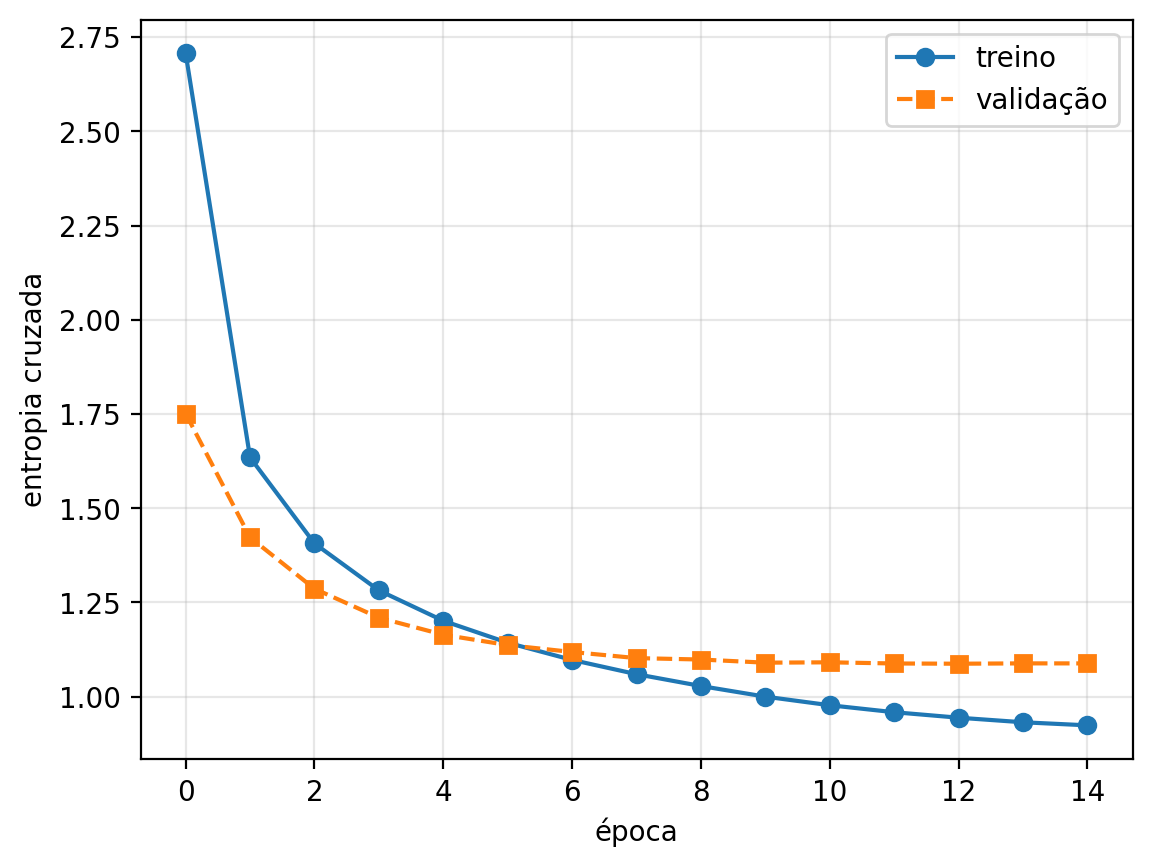


Entropia cruzada no teste 1.1031 | Perplexidade no teste 3.01


In [ ]:
# CARREGAMENTO DOS DADOS
d = pickle.load(open("tokens.pkl", "rb"))
dataset, V = d["dataset"], d["V"]
PAD, BOS, EOS, SEP, MAX_LEN = d["PAD"], d["BOS"], d["EOS"], d["SEP"], d["MAX_LEN"]

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
dev = "cuda" if torch.cuda.is_available() else "cpu"
AC = dict(device_type=dev, dtype=torch.float16, enabled=(dev == "cuda"))
print("Dispositivo:", dev, "| vocabulário:", V, "| janelas (treino/val/teste):", {k: len(v) for k, v in dataset.items()})

# EXECUÇÃO DO TRANSFORMER
EPOCHS = 15
model_tf = PianoTransformer(V)
print("")
print(f"Número de Parâmetros: {sum(p.numel() for p in model_tf.parameters())}")
model_tf, hist_tf = treinar(model_tf, epocas=EPOCHS)

# GRÁFICO DE TREINAMENTO
print("")
plt.plot(hist_tf["train"], "o-", label="treino")
plt.plot(hist_tf["val"], "s--", label="validação")
plt.xlabel("época")
plt.ylabel("entropia cruzada")
plt.legend()
plt.grid(alpha=.3)
plt.show()

# ENTROPIA CRUZADA E PERPLEXIDADE
test_dataset = PianoDataset(dataset["test"])
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
test_loss = avaliar(model_tf, test_loader)
print("")
print(f"Entropia cruzada no teste {test_loss:.4f} | Perplexidade no teste {math.exp(test_loss):.2f}")

json.dump(hist_tf, open("hist_transformer.json", "w"))

#### 5.2 - Execução da RNN

Número de Parâmetros: 4929228
época 1/15: treino 2.0755 | val 1.5891 (ppl 4.90) | 19s
época 2/15: treino 1.4593 | val 1.4136 (ppl 4.11) | 19s
época 3/15: treino 1.3265 | val 1.3776 (ppl 3.97) | 19s
época 4/15: treino 1.2440 | val 1.3631 (ppl 3.91) | 19s
época 5/15: treino 1.1772 | val 1.3437 (ppl 3.83) | 19s
época 6/15: treino 1.1222 | val 1.3432 (ppl 3.83) | 19s
época 7/15: treino 1.0666 | val 1.3445 (ppl 3.84) | 19s
época 8/15: treino 1.0146 | val 1.3633 (ppl 3.91) | 19s
época 9/15: treino 0.9648 | val 1.3656 (ppl 3.92) | 19s
Early stopping.



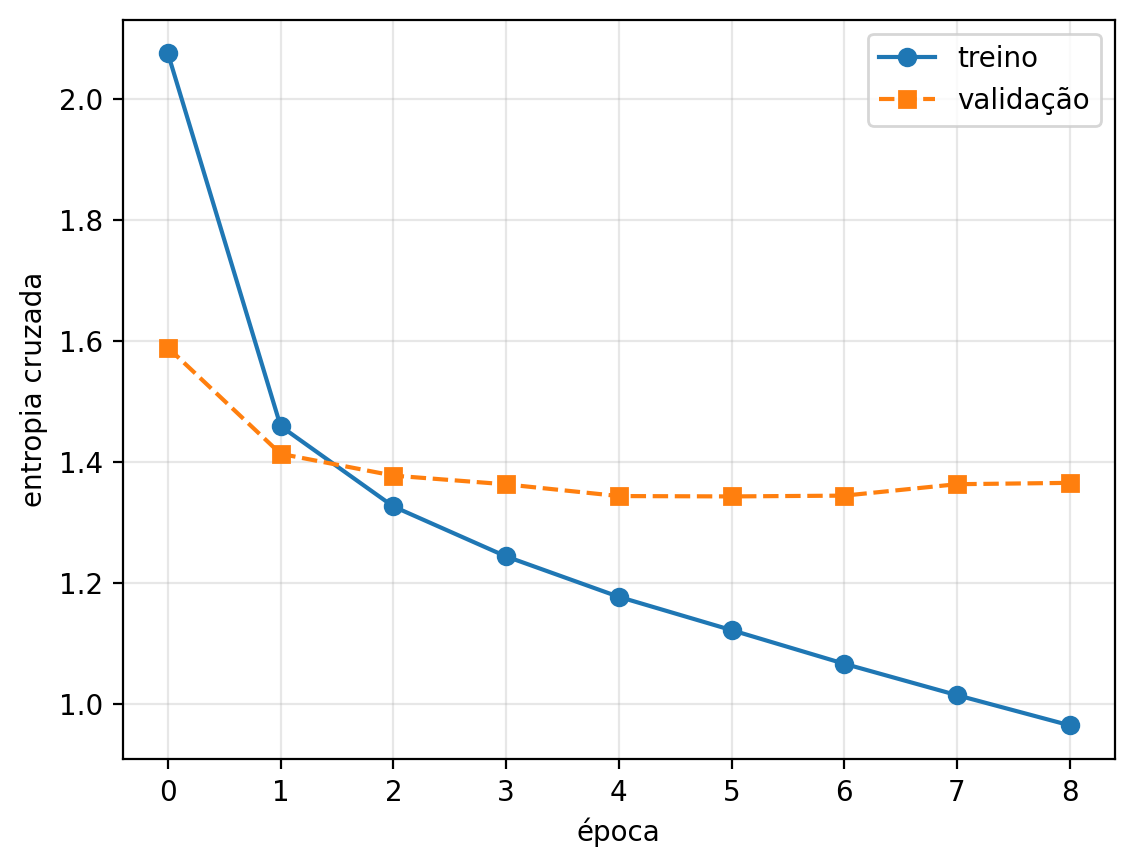


Entropia cruzada no teste 1.3673 | Perplexidade no teste 3.92


In [ ]:
set_seed = lambda s: (random.seed(s), np.random.seed(s), torch.manual_seed(s))
set_seed(SEED)

rnn = VanillaRNN(V)
print(f"Número de Parâmetros: {sum(p.numel() for p in rnn.parameters())}")

rnn, hist_rnn = treinar(rnn, epocas=EPOCHS, lr=1e-3, caminho="rnn_vanilla.pt")

print("")
plt.plot(hist_rnn["train"], "o-", label="treino")
plt.plot(hist_rnn["val"], "s--", label="validação")
plt.xlabel("época")
plt.ylabel("entropia cruzada")
plt.legend()
plt.grid(alpha=.3)
plt.show()

test_loss_rnn = avaliar(rnn, test_loader)
print("")
print(f"Entropia cruzada no teste {test_loss_rnn:.4f} | Perplexidade no teste {math.exp(test_loss_rnn):.2f}")

json.dump(hist_rnn, open("hist_rnn_vanilla.json", "w"))
json.dump(hist_tf, open("hist_transformer.json", "w"))

#### 5.3 - Curva de Treinamento dos Modelos

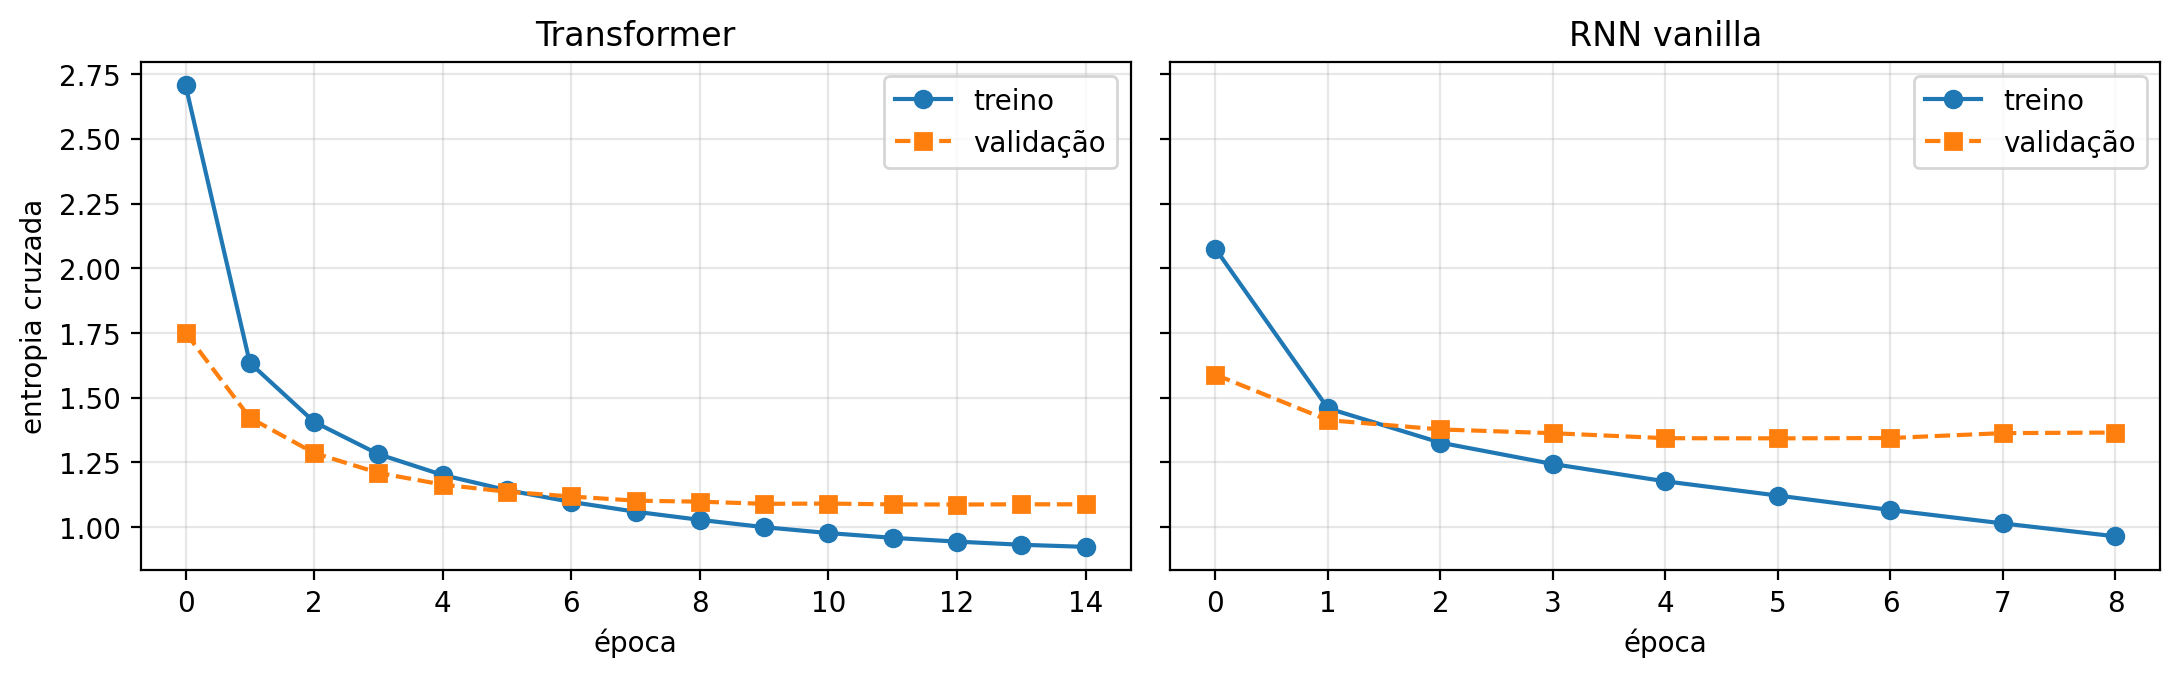

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, (nome, h) in zip(ax, [("Transformer", hist_tf), ("RNN vanilla", hist_rnn)]):
    a.plot(h["train"], "o-", label="treino")
    a.plot(h["val"], "s--", label="validação")
    a.set_title(nome)
    a.set_xlabel("época")
    a.grid(alpha=.3)
    a.legend()
ax[0].set_ylabel("entropia cruzada")
plt.tight_layout()
plt.show()

#### 5.4 - Geração das Amostras

In [ ]:
# PARÂMETROS DA GERAÇÃO
meta = pickle.load(open("tokens.pkl", "rb"))
BAR_ID, WIN_BARS = meta["BAR"], meta["WIN_BARS"]
T = WIN_BARS * 16
N_GEN, TEMP, TOP_P = 100, 1.0, 0.95
test = dataset["test"]

# GERAÇÃO DAS AMOSTRAS
sel = np.random.RandomState(42).choice(len(test), N_GEN, replace=False)
geradas = {"Transformer": [], "RNN vanilla": []}
for nome, m in [("Transformer", model_tf), ("RNN vanilla", rnn)]:
    torch.manual_seed(42)
    random.seed(42)
    np.random.seed(42)
    for i in tqdm(sel, desc=f"Gerando ({nome})"):
        ids, ok = gerar(m, test[i]["mel"], temperatura=TEMP, top_k=0, top_p=TOP_P)
        geradas[nome].append({"idx": int(i), "ids": ids, "eos": ok})
pickle.dump({"sel": sel, "geradas": geradas}, open("geradas.pkl", "wb"))

Gerando (Transformer):   0%|          | 0/100 [00:00<?, ?it/s]

Gerando (RNN vanilla):   0%|          | 0/100 [00:00<?, ?it/s]

#### 5.5 - Definição das Métricas Objetivas

In [ ]:
def metricas(t, du, p):
    if len(t) < 2:
        return None

    music = muspy.Music()
    track = muspy.Track(program=0, is_drum=False)
    for a, b, c in zip(t, du, p):
        track.notes.append(muspy.Note(time=int(a), duration=int(b), pitch=int(c), velocity=80))
    music.tracks.append(track)
    music.resolution = 4

    try:
        return {
            "pitch_class_entropy": float(muspy.pitch_class_entropy(music)),
            "polyphony": float(muspy.polyphony(music)),
            "empty_beat_rate": float(muspy.empty_beat_rate(music)),
            "scale_consistency": float(muspy.scale_consistency(music)),
            "pitch_range": float(muspy.pitch_range(music))
        }
    except Exception:
        return None

#### 5.6 - Cálculo das Métricas Objetivas

In [ ]:
def tabela(lista_ids):
    linhas = [metricas(*destokenizar(ids)) for ids in lista_ids]
    return pd.DataFrame([l for l in linhas if l is not None])


M = {"Humano (teste)": tabela([x["acc"] for x in test])}
for nome, g in geradas.items():
    M[nome] = tabela([x["ids"] for x in g])
print("\nAmostras com métricas válidas:", {k: len(v) for k, v in M.items()})
METRICAS = list(M["Humano (teste)"].columns)

resumo = pd.DataFrame({k: v.agg(["mean", "std"]).T.apply(lambda r: f"{r["mean"]:.3f} ± {r["std"]:.3f}", axis=1) for k, v in M.items()})
print("\nTABELA DE MÉTRICAS OBJETIVAS")
print(resumo.to_string())


resumo.to_csv("metricas_resumo.csv")


Amostras com métricas válidas: {'Humano (teste)': 1495, 'Transformer': 100, 'RNN vanilla': 100}

TABELA DE MÉTRICAS OBJETIVAS
                     Humano (teste)     Transformer     RNN vanilla
pitch_class_entropy   2.604 ± 0.219   2.566 ± 0.263   2.572 ± 0.449
polyphony             2.825 ± 0.530   2.653 ± 0.386   2.532 ± 0.404
empty_beat_rate       0.008 ± 0.036   0.000 ± 0.000   0.001 ± 0.004
scale_consistency     0.984 ± 0.035   0.981 ± 0.039   0.935 ± 0.076
pitch_range          29.573 ± 5.129  27.670 ± 3.840  28.480 ± 6.006


#### 5.7 - Comparação das Distribuições
**Cálculo da distribuição das métricas implementado seguindo a implementação de Yang & Lerch (2020)**

**FONTE: https://github.com/RichardYang40148/mgeval**


TABELA DE DISTRIBUIÇÃO DAS MÉTRICAS

            métrica        sistema  dist. à média do teste  |Δ média|  OA inter (↑)  KL inter (↓)  OA intra (↑)  KL intra (↓)
pitch_class_entropy Humano (teste)                  0.1592     0.0000           NaN           NaN           NaN           NaN
pitch_class_entropy    Transformer                  0.1895     0.0380        0.9529        0.0091        0.9056        0.0361
pitch_class_entropy    RNN vanilla                  0.3484     0.0324        0.7367        0.2066        0.6295        0.3979
          polyphony Humano (teste)                  0.4120     0.0000           NaN           NaN           NaN           NaN
          polyphony    Transformer                  0.3453     0.1713        0.9614        0.0131        0.8438        0.2077
          polyphony    RNN vanilla                  0.3865     0.2926        0.9836        0.0040        0.8665        0.1233
    empty_beat_rate Humano (teste)                  0.0152     0.0000           

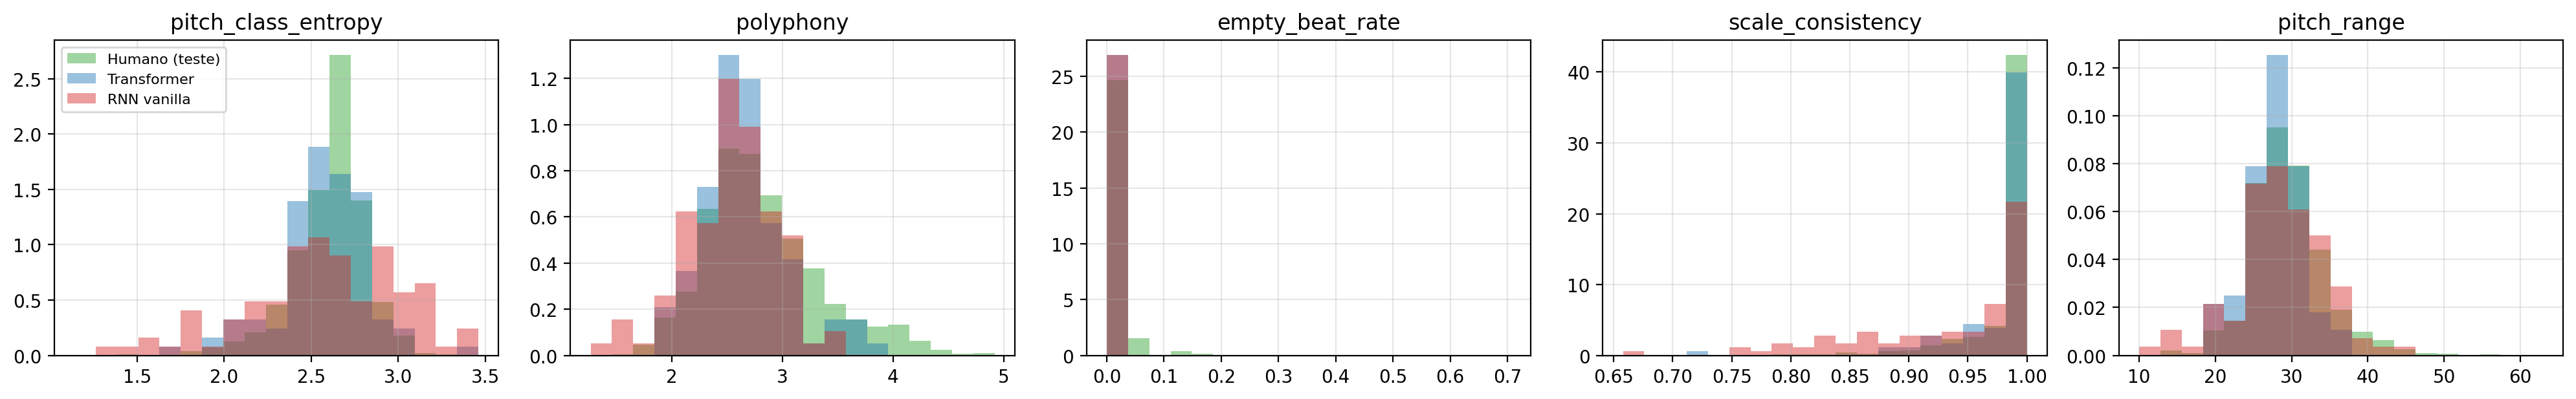

In [ ]:
trap = getattr(np, "trapezoid", None) or np.trapz

# FUNÇÕES PARA CÁLCULO DE DISTRIBUIÇÃO DAS MÉTRICAS
def pares_intra(x):
    i, j = np.triu_indices(len(x), 1)
    return np.abs(x[i] - x[j])

def pares_inter(a, b):
    return np.abs(a[:, None] - b[None, :]).ravel()

def pdf_kde(s, g):
    h = max(1.06 * s.std() * len(s) ** (-0.2), 0.01 * g[-1])
    k = np.exp(-0.5 * ((g[:, None] - s[None, :]) / h) ** 2).mean(1)
    return k / trap(k, g)

def oa_kl(a, b, rs, n=2000):
    a = rs.choice(a, min(n, len(a)), replace=False)
    b = rs.choice(b, min(n, len(b)), replace=False)
    g = np.linspace(0, max(a.max(), b.max(), 1e-3), 400)
    p, q = pdf_kde(a, g), pdf_kde(b, g)
    return float(trap(np.minimum(p, q), g)), float(trap(p * np.log((p + 1e-12) / (q + 1e-12)), g))

# TABELA DE DISTRIBUIÇÃO DAS MÉTRICAS
rs = np.random.RandomState(0)
print("")
print("TABELA DE DISTRIBUIÇÃO DAS MÉTRICAS\n")
linhas = []
for met in METRICAS:
    ref = M["Humano (teste)"][met].values
    ref_intra = pares_intra(ref)
    mu = ref.mean()
    linhas.append({"métrica": met, "sistema": "Humano (teste)", "dist. à média do teste": np.abs(ref - mu).mean(),
                   "|Δ média|": 0.0, "OA inter (↑)": np.nan, "KL inter (↓)": np.nan, "OA intra (↑)": np.nan, "KL intra (↓)": np.nan})
    for nome in geradas:
        g = M[nome][met].values
        oa_e, kl_e = oa_kl(ref_intra, pares_inter(g, ref), rs)
        oa_i, kl_i = oa_kl(ref_intra, pares_intra(g), rs)
        linhas.append({"métrica": met, "sistema": nome, "dist. à média do teste": np.abs(g - mu).mean(),
                       "|Δ média|": abs(g.mean() - mu), "OA inter (↑)": oa_e, "KL inter (↓)": kl_e,
                       "OA intra (↑)": oa_i, "KL intra (↓)": kl_i})
dist = pd.DataFrame(linhas).round(4)
print(dist.to_string(index=False))
dist.to_csv("metricas_distribuicoes.csv", index=False)

# MÉDIA DAS MÉTRICAS DE DISTRIBUIÇÃO POR SISTEMA
print("")
print("TABELA DE MÉDIAS DAS MÉTRICAS DE DISTRIBUIÇÃO POR SISTEMA\n")
print(dist[dist["sistema"] != "Humano (teste)"].groupby("sistema")[["dist. à média do teste", "|Δ média|", "OA inter (↑)", "KL inter (↓)", "OA intra (↑)", "KL intra (↓)"]].mean().round(4).to_string())

# GRÁFICOS DAS DISTRIBUIÇÕES DAS MÉTRICAS
print("")
cores = {"Humano (teste)": "tab:green", "Transformer": "tab:blue", "RNN vanilla": "tab:red"}
fig, ax = plt.subplots(1, len(METRICAS), figsize=(4 * len(METRICAS), 3.2))
for a, met in zip(ax, METRICAS):
    todos = np.concatenate([M[k][met].values for k in M])
    bins = np.linspace(todos.min(), todos.max() + 1e-9, 20)
    for k in M:
        a.hist(M[k][met].values, bins=bins, density=True, alpha=.45, label=k, color=cores[k])
    a.set_title(met)
    a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("distribuicoes_metricas.png", dpi=150)
plt.show()

### 6 - Renderização e Salvamento

In [ ]:
g = pickle.load(open("geradas.pkl", "rb"))
sel, geradas = g["sel"], g["geradas"]
test = dataset["test"]
N_SAVE = 5

for pasta in ("saida/midi", "saida/audio", "saida/figs"):
    os.makedirs(pasta, exist_ok=True)

SF2 = next((p for p in ["/usr/share/sounds/sf2/FluidR3_GM.sf2", "/usr/share/soundfonts/FluidR3_GM.sf2"] if os.path.exists(p)), None)
print("SoundFont:", SF2)
assert SF2, "SoundFont não encontrado: rode a célula de instalação."

def salvar(nome, mel_ids, acc_ids, bpm):
    bpm = 100.0 if (bpm is None or not np.isfinite(bpm)) else float(np.clip(bpm, 40, 220))
    sec = 60.0 / bpm / 4
    pm = pretty_midi.PrettyMIDI(initial_tempo=bpm)
    for ids, prog, nm, vel in ((mel_ids, 73, "melodia", 90), (acc_ids, 0, "acompanhamento", 70)):
        t, du, p = destokenizar(ids)
        inst = pretty_midi.Instrument(program=prog, name=nm)
        for a, b, c in zip(t, du, p):
            inst.notes.append(pretty_midi.Note(velocity=vel, pitch=int(c), start=float(a * sec), end=float((a + b) * sec)))
        pm.instruments.append(inst)
    pm.write(f"saida/midi/{nome}.mid")
    try:
        audio = pm.fluidsynth(fs=22050, sf2_path=SF2)
        audio = audio / max(1e-6, np.abs(audio).max()) * 0.9
        wavfile.write(f"saida/audio/{nome}.wav", 22050, (audio * 32767).astype(np.int16))
    except Exception as e:
        print("Falha ao sintetizar", nome, "->", type(e).__name__, e)

for j in range(N_SAVE):
    i = int(sel[j])
    it = test[i]
    assert geradas["Transformer"][j]["idx"] == i and geradas["RNN vanilla"][j]["idx"] == i
    salvar(f"humano_{j+1:02d}", it["mel"], it["acc"], it["bpm"])
    salvar(f"transformer_{j+1:02d}", it["mel"], geradas["Transformer"][j]["ids"], it["bpm"])
    salvar(f"rnn_vanilla_{j+1:02d}", it["mel"], geradas["RNN vanilla"][j]["ids"], it["bpm"])

SoundFont: /usr/share/sounds/sf2/FluidR3_GM.sf2


/tmp/ipykernel_1913/4215093378.py:25: DeprecationWarning: The parameter 'sf2_path' is deprecated, please use 'synthesizer' instead.
  audio = pm.fluidsynth(fs=22050, sf2_path=SF2)


In [ ]:
# EXEMPLO
print("")
for nome in ("humano_01", "transformer_01", "rnn_vanilla_01"):
    print(nome)
    display(Audio(f"saida/audio/{nome}.wav"))


humano_01


transformer_01


rnn_vanilla_01


In [ ]:
linhas = []
for j in range(N_SAVE):
    it = test[int(sel[j])]
    linhas.append({"exemplo": j + 1,
                   "notas humano": len(destokenizar(it["acc"])[0]), "compassos humano": it["acc"].count(BAR_ID),
                   "notas Transformer": len(destokenizar(geradas["Transformer"][j]["ids"])[0]),
                   "compassos Transformer": geradas["Transformer"][j]["ids"].count(BAR_ID),
                   "notas RNN": len(destokenizar(geradas["RNN vanilla"][j]["ids"])[0]),
                   "compassos RNN": geradas["RNN vanilla"][j]["ids"].count(BAR_ID)})
print("TABELA DE NÚMERO DE NOTAS E COMPASSOS POR SISTEMA")
print(pd.DataFrame(linhas).to_string(index=False))

TABELA DE NÚMERO DE NOTAS E COMPASSOS POR SISTEMA
 exemplo  notas humano  compassos humano  notas Transformer  compassos Transformer  notas RNN  compassos RNN
       1            33                 4                 32                      4        144              7
       2            60                 4                 48                      4         10              1
       3            30                 4                 53                      4         23              1
       4            42                 4                 43                      4         39              3
       5            58                 4                 39                      4        134              6


In [ ]:
for f in (
    "metricas_resumo.csv",
    "metricas_distribuicoes.csv",
    "distribuicoes_metricas.png",
    "hist_transformer.json",
    "hist_rnn_vanilla.json",
    "particao.json",
):
    if os.path.exists(f):
        shutil.copy(f, "saida/")

shutil.make_archive("saida", "zip", "saida")

try:
    from google.colab import files
    files.download("saida.zip")
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>